## Smoke test PatchCore sur Bottle
Version Kaggle GPU [v3](https://www.kaggle.com/code/marwanedrissi/industrialdefect-ai-patchcore-bottle-smoke?scriptVersionId=368924991). Exécuter sur un GPU avec Internet et l’entrée ipythonx/mvtec-ad. La copie Git conserve les sorties Kaggle des cellules réussies. L’initialisation a été séparée du contrôle du gel pour permettre une exécution séquentielle.

In [4]:
import os
import sys
import shutil
import subprocess
import importlib.metadata as metadata

import torch
import torchvision

print("=== ENVIRONMENT ===")
print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("Kaggle:", os.path.exists("/kaggle"))
print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

print("\n=== DEPENDENCIES ===")

for package in ["anomalib", "timm", "lightning"]:
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        print(package, "NOT INSTALLED")

print("\n=== GPU ===")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No CUDA GPU detected")

if shutil.which("nvidia-smi"):
    subprocess.run(["nvidia-smi"], check=False)
else:
    print("nvidia-smi not available")

print("\n=== PRE-FLIGHT ===")

assert os.path.exists("/kaggle"), (
    "This validation must run on Kaggle"
)

assert torch.cuda.is_available(), (
    "Enable the GPU accelerator in Kaggle"
)

print("Kaggle GPU environment: OK")


=== ENVIRONMENT ===
Python: 3.13.16
Executable: /usr/bin/python3
Kaggle: True
Torch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA runtime: 13.0
CUDA available: True

=== DEPENDENCIES ===
anomalib 2.7.0
timm 1.0.30
lightning 2.6.6

=== GPU ===
GPU: Tesla T4
Thu Nov 12 20:13:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |

In [5]:
import sys
import json
import subprocess
from pathlib import Path

report_path = Path("/kaggle/working/patchcore_install_plan.json")

result = subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--dry-run",
        "--report", str(report_path),
        "anomalib==2.7.0"
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("Dependency resolution failed")

report = json.loads(report_path.read_text())

planned = sorted(
    item["metadata"]["name"]
    for item in report["install"]
)

print("=== PLANNED INSTALLATIONS ===")
for name in planned:
    print(name)

critical = {
    "torch", "torchvision", "torchaudio",
    "triton"
}

changes = critical.intersection(
    name.lower().replace("_", "-")
    for name in planned
)

print("\n=== PYTORCH CHECK ===")
print("Critical packages to change:", sorted(changes))

assert not changes, (
    "Installation would modify PyTorch/CUDA packages"
)

print("\nDependency plan: OK")

=== PLANNED INSTALLATIONS ===

=== PYTORCH CHECK ===
Critical packages to change: []

Dependency plan: OK


In [6]:
import sys
import subprocess

subprocess.run(
    [
        sys.executable, "-m", "pip",
        "install", "anomalib==2.7.0"
    ],
    check=True
)

print("Installation completed")

Installation completed


In [7]:
import importlib.metadata as metadata
import torch
import torchvision
import timm
import anomalib

print("=== FINAL VERSIONS ===")

for package in [
    "torch",
    "torchvision",
    "timm",
    "anomalib",
    "lightning"
]:
    print(f"{package}: {metadata.version(package)}")

print("\n=== GPU ===")
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

assert torch.__version__ == "2.11.0+cu130"
assert torchvision.__version__ == "0.26.0+cu130"
assert metadata.version("anomalib") == "2.7.0"
assert torch.cuda.is_available()

print("\nPatchCore dependencies: OK")


=== FINAL VERSIONS ===
torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
timm: 1.0.30
anomalib: 2.7.0
lightning: 2.6.6

=== GPU ===
CUDA available: True
GPU: Tesla T4

PatchCore dependencies: OK


In [ ]:
# Vérifier également les dépendances indirectes du run enregistré.
assert sys.version_info[:3] == (3, 13, 16)
assert metadata.version("timm") == "1.0.30"
assert metadata.version("lightning") == "2.6.6"

In [ ]:
import torch
from anomalib.models.image.patchcore.torch_model import PatchcoreModel

DEVICE = torch.device("cuda:0")
BACKBONE = "wide_resnet50_2"
LAYERS = ["layer2", "layer3"]

model = PatchcoreModel(
    backbone=BACKBONE,
    layers=LAYERS,
    pre_trained=True,
    num_neighbors=1,
).to(DEVICE)

In [9]:

# ST-04-01-01 — Freeze pretrained backbone

# Disable gradient computation for the feature extractor
model.feature_extractor.requires_grad_(False)

# Keep the model in evaluation mode
model.eval()

total_params = sum(
    p.numel()
    for p in model.feature_extractor.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.feature_extractor.parameters()
    if p.requires_grad
)

print("=== BACKBONE VALIDATION ===")
print("Backbone:", BACKBONE)
print("Layers:", LAYERS)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Training mode:", model.training)

assert trainable_params == 0
assert not model.training

print("\nBackbone frozen: OK")


=== BACKBONE VALIDATION ===
Backbone: wide_resnet50_2
Layers: ['layer2', 'layer3']
Total parameters: 24862528
Trainable parameters: 0
Training mode: False

Backbone frozen: OK


In [10]:
# ST-04-01-01 — Feature extraction validation

dummy_batch = torch.randn(
    1, 3, 256, 256,
    device=DEVICE
)

with torch.inference_mode():
    features = model.feature_extractor(dummy_batch)

print("=== FEATURE EXTRACTION ===")

for layer in LAYERS:
    assert layer in features, f"Missing layer: {layer}"

    feature_map = features[layer]

    print(f"\n{layer}")
    print("Shape:", tuple(feature_map.shape))
    print("Dtype:", feature_map.dtype)
    print("Device:", feature_map.device)
    print("Finite:", torch.isfinite(feature_map).all().item())

    assert feature_map.ndim == 4
    assert feature_map.device.type == "cuda"
    assert torch.isfinite(feature_map).all()

print("\nFeature extraction: OK")

=== FEATURE EXTRACTION ===

layer2
Shape: (1, 512, 32, 32)
Dtype: torch.float32
Device: cuda:0
Finite: True

layer3
Shape: (1, 1024, 16, 16)
Dtype: torch.float32
Device: cuda:0
Finite: True

Feature extraction: OK


### Données et banque mémoire
Le split provient du manifeste versionné. Les huit images normales alimentent la banque. Anomalib renvoie déjà une matrice de patches 2D.

In [11]:
from pathlib import Path
import subprocess
import sys

REPO_URL = "https://github.com/MRdrissi/industrial-defect-ai.git"
REPO_DIR = Path("/kaggle/working/industrial-defect-ai")
BASE_COMMIT = "0a6f5fa"

if not (REPO_DIR / ".git").exists():
    subprocess.run(
        ["git", "clone", "--quiet", REPO_URL, str(REPO_DIR)],
        check=True
    )

subprocess.run(
    ["git", "-C", str(REPO_DIR), "checkout",
     "--detach", BASE_COMMIT],
    check=True
)

commit = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    text=True
).strip()

assert commit.startswith(BASE_COMMIT)

sys.path.insert(0, str(REPO_DIR))

from src.data.mvtec_dataset import MVTecDataset
from src.data.transforms import MVTecTransform
from src.data.dataloaders import create_dataloader

print("Repository commit:", commit)
print("US-02-04 imports: OK")

Repository commit: 0a6f5fac7b47fcaa797d65774e7442ed0201de1f
US-02-04 imports: OK


HEAD is now at 0a6f5fa merge: integrate EPIC-01 and EPIC-02 into develop


In [12]:
import os
import torch
from pathlib import Path

# Locate MVTec dataset root
dataset_root = None

for current, dirs, _ in os.walk("/kaggle/input"):
    candidate = Path(current)

    if "bottle" in dirs and (
        candidate / "bottle" / "train" / "good"
    ).is_dir():
        dataset_root = candidate
        break

assert dataset_root is not None, (
    "MVTec AD dataset not found. Add it as Kaggle Input."
)

manifest = (
    REPO_DIR / "docs/data/us-02-03/bottle_manifest.csv"
)

transform = MVTecTransform(
    size=(256, 256),
    profile="patchcore"
)

train_dataset = MVTecDataset(
    dataset_root=dataset_root,
    manifest_path=manifest,
    category="bottle",
    split="train",
    transform=transform
)

train_loader = create_dataloader(
    train_dataset,
    batch_size=2,
    num_workers=0,
    seed=42
)

batch = next(iter(train_loader))
images = batch["image"].to(DEVICE)

print("=== REAL BOTTLE BATCH ===")
print("Dataset root:", dataset_root)
print("Train samples:", len(train_dataset))
print("Image shape:", tuple(images.shape))
print("Dtype:", images.dtype)
print("Min:", images.min().item())
print("Max:", images.max().item())
print("Labels:", batch["label"].tolist())
print("Paths:", batch["image_path"])

assert len(train_dataset) == 167
assert images.shape == (2, 3, 256, 256)
assert torch.isfinite(images).all()
assert torch.all(batch["label"] == 0)

print("\nMVTec Bottle pipeline: OK")

=== REAL BOTTLE BATCH ===
Dataset root: /kaggle/input/datasets/ipythonx/mvtec-ad
Train samples: 167
Image shape: (2, 3, 256, 256)
Dtype: torch.float32
Min: -1.621286153793335
Max: 2.640000104904175
Labels: [0, 0]
Paths: ['bottle/train/good/129.png', 'bottle/train/good/150.png']

MVTec Bottle pipeline: OK


In [13]:
with torch.inference_mode():
    real_features = model.feature_extractor(images)

print("=== REAL BOTTLE FEATURES ===")

for layer in LAYERS:
    tensor = real_features[layer]

    print(layer, tuple(tensor.shape))
    assert torch.isfinite(tensor).all()

print("\nReal-image feature extraction: OK")


=== REAL BOTTLE FEATURES ===
layer2 (2, 512, 32, 32)
layer3 (2, 1024, 16, 16)

Real-image feature extraction: OK


In [14]:
from torch.utils.data import Subset, DataLoader

SEED = 42
NUM_IMAGES = 8
BATCH_SIZE = 2

generator = torch.Generator().manual_seed(SEED)

selected_indices = torch.randperm(
    len(train_dataset),
    generator=generator
)[:NUM_IMAGES].tolist()

smoke_dataset = Subset(train_dataset, selected_indices)

smoke_loader = DataLoader(
    smoke_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

selected_paths = [
    train_dataset[i]["image_path"]
    for i in selected_indices
]

print("=== PATCHCORE TRAIN SELECTION ===")
print("Selected images:", len(smoke_dataset))

for path in selected_paths:
    print(path)

assert len(smoke_dataset) == 8
assert len(set(selected_paths)) == 8
assert all("/train/good/" in p for p in selected_paths)

print("\nTraining subset: OK")

=== PATCHCORE TRAIN SELECTION ===
Selected images: 8
bottle/train/good/028.png
bottle/train/good/039.png
bottle/train/good/043.png
bottle/train/good/117.png
bottle/train/good/181.png
bottle/train/good/175.png
bottle/train/good/206.png
bottle/train/good/115.png

Training subset: OK


In [16]:

# ST-04-01-02 — Extract patch embeddings

model.train()  # PatchCore returns embeddings in training mode
model.feature_extractor.eval()  # Keep backbone in eval mode

patch_vectors = []

with torch.inference_mode():
    for batch_idx, batch in enumerate(smoke_loader):
        images = batch["image"].to(DEVICE)

        # Already flattened: [B * H * W, D]
        embeddings = model(images)

        if batch_idx == 0:
            print("First batch shape:", tuple(embeddings.shape))

        assert isinstance(embeddings, torch.Tensor)
        assert embeddings.ndim == 2
        assert embeddings.shape[0] == images.shape[0] * 32 * 32
        assert torch.isfinite(embeddings).all()

        patch_vectors.append(embeddings.detach())

all_embeddings = torch.cat(patch_vectors, dim=0)

print("\n=== PATCH EMBEDDINGS ===")
print("Training images:", NUM_IMAGES)
print("Embedding matrix:", tuple(all_embeddings.shape))
print("Dtype:", all_embeddings.dtype)
print("Device:", all_embeddings.device)
print("Finite:", torch.isfinite(all_embeddings).all().item())

assert all_embeddings.shape == (8192, 1536)
assert torch.isfinite(all_embeddings).all()

print("\nPatch embeddings: OK")


First batch shape: (2048, 1536)

=== PATCH EMBEDDINGS ===
Training images: 8
Embedding matrix: (8192, 1536)
Dtype: torch.float32
Device: cuda:0
Finite: True

Patch embeddings: OK


In [17]:
# ST-04-01-02 — Build minimal Memory Bank

import torch
from anomalib.models.components import KCenterGreedy

SEED = 42
CORESET_RATIO = 0.10

torch.manual_seed(SEED)

print("=== CORESET SAMPLING ===")
print("Original embeddings:", tuple(all_embeddings.shape))
print("Sampling ratio:", CORESET_RATIO)

sampler = KCenterGreedy(
    embedding=all_embeddings.detach(),
    sampling_ratio=CORESET_RATIO
)

coreset = sampler.sample_coreset()

# Store the selected patches in PatchCore
model.memory_bank = coreset.detach().contiguous()

# Switch PatchCore from embedding extraction to inference
model.eval()

bank = model.memory_bank

print("\n=== MEMORY BANK ===")
print("Bank shape:", tuple(bank.shape))
print("Device:", bank.device)
print("Dtype:", bank.dtype)
print("Finite:", torch.isfinite(bank).all().item())

assert bank.ndim == 2
assert bank.shape[1] == 1536
assert 0 < bank.shape[0] < all_embeddings.shape[0]
assert torch.isfinite(bank).all()
assert not model.training

print("\nMemory Bank: OK")


=== CORESET SAMPLING ===
Original embeddings: (8192, 1536)
Sampling ratio: 0.1


Selecting Coreset Indices.: 100%|██████████| 818/818 [00:00<00:00, 2854.67it/s]


=== MEMORY BANK ===
Bank shape: (819, 1536)
Device: cuda:0
Dtype: torch.float32
Finite: True

Memory Bank: OK


In [18]:
# ST-04-01-02 — First validation inference

val_dataset = MVTecDataset(
    dataset_root=dataset_root,
    manifest_path=manifest,
    category="bottle",
    split="val",
    transform=transform
)

assert len(val_dataset) == 42

sample = val_dataset[0]

assert int(sample["label"]) == 0

val_image = sample["image"].unsqueeze(0).to(DEVICE)

with torch.inference_mode():
    prediction = model(val_image)

score = prediction.pred_score
anomaly_map = prediction.anomaly_map

print("=== FIRST PATCHCORE INFERENCE ===")
print("Image:", sample["image_path"])
print("Input:", tuple(val_image.shape))
print("Score:", score.detach().cpu().tolist())
print("Anomaly map:", tuple(anomaly_map.shape))
print("Map min:", anomaly_map.min().item())
print("Map max:", anomaly_map.max().item())

assert score.numel() == 1
assert torch.isfinite(score).all()
assert torch.isfinite(anomaly_map).all()
assert anomaly_map.shape[-2:] == (256, 256)

print("\nPatchCore inference: OK")

=== FIRST PATCHCORE INFERENCE ===
Image: bottle/train/good/002.png
Input: (1, 3, 256, 256)
Score: [30.64944839477539]
Anomaly map: (1, 1, 256, 256)
Map min: 2.3115618228912354
Map max: 29.849456787109375

PatchCore inference: OK


In [19]:

from pathlib import Path
import hashlib
import json
import importlib.metadata as metadata

RUN_DIR = Path(
    "/kaggle/working/patchcore/bottle/smoke-001"
)
RUN_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = RUN_DIR / "patchcore_model.pt"

state = {
    key: tensor.detach().cpu().contiguous()
    for key, tensor in model.state_dict().items()
}

assert "memory_bank" in state
assert tuple(state["memory_bank"].shape) == (819, 1536)

torch.save(
    {
        "model_state_dict": state,
        "backbone": BACKBONE,
        "layers": LAYERS,
        "num_neighbors": 1,
    },
    checkpoint_path
)

checkpoint_sha256 = hashlib.sha256(
    checkpoint_path.read_bytes()
).hexdigest()

report = {
    "run_id": "patchcore-bottle-smoke-001",
    "git_commit": commit,
    "manifest_sha256": hashlib.sha256(
        manifest.read_bytes()
    ).hexdigest(),
    "versions": {
        package: metadata.version(package)
        for package in [
            "torch", "torchvision",
            "anomalib", "timm", "lightning"
        ]
    },
    "backbone": BACKBONE,
    "layers": LAYERS,
    "seed": SEED,
    "train_images": selected_paths,
    "coreset_ratio": CORESET_RATIO,
    "embedding_shape": list(all_embeddings.shape),
    "memory_bank_shape": list(bank.shape),
    "validation_image": sample["image_path"],
    "anomaly_score": float(score.item()),
    "anomaly_map_shape": list(anomaly_map.shape),
    "checkpoint_sha256": checkpoint_sha256
}

(RUN_DIR / "smoke_report.json").write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("Checkpoint:", checkpoint_path)
print("SHA256:", checkpoint_sha256)
print("Report saved:", RUN_DIR / "smoke_report.json")
print("Artifacts saved: OK")


Checkpoint: /kaggle/working/patchcore/bottle/smoke-001/patchcore_model.pt
SHA256: 37e3d731aca54d2f0272b79082d21eeafebc96faeda91d19a72a84353451a9fa
Report saved: /kaggle/working/patchcore/bottle/smoke-001/smoke_report.json
Artifacts saved: OK


In [20]:

from anomalib.models.image.patchcore.torch_model import PatchcoreModel

saved = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

restored_model = PatchcoreModel(
    backbone=saved["backbone"],
    layers=saved["layers"],
    pre_trained=False,
    num_neighbors=saved["num_neighbors"]
)

restored_model.load_state_dict(
    saved["model_state_dict"],
    strict=True
)

restored_model = restored_model.to(DEVICE)
restored_model.feature_extractor.requires_grad_(False)
restored_model.eval()

with torch.inference_mode():
    restored_prediction = restored_model(val_image)

torch.testing.assert_close(
    restored_prediction.pred_score,
    score,
    rtol=1e-5,
    atol=1e-4
)

torch.testing.assert_close(
    restored_prediction.anomaly_map,
    anomaly_map,
    rtol=1e-5,
    atol=1e-4
)

print("=== RESTORATION CHECK ===")
print("Memory Bank:", tuple(restored_model.memory_bank.shape))
print("Original score:", score.item())
print("Restored score:", restored_prediction.pred_score.item())
print("Score and anomaly map: MATCH")
print("\nRestoration: OK")


=== RESTORATION CHECK ===
Memory Bank: (819, 1536)
Original score: 30.64944839477539
Restored score: 30.64944839477539
Score and anomaly map: MATCH

Restoration: OK


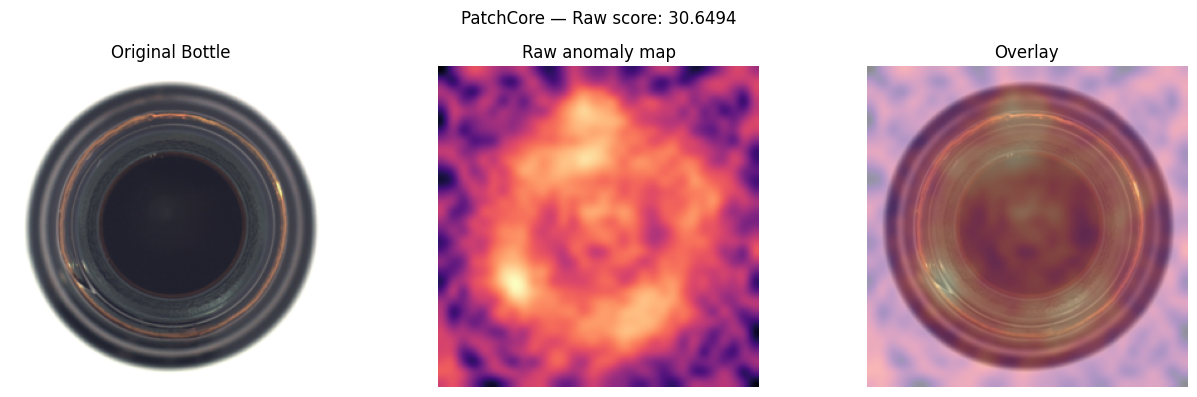

In [21]:

import matplotlib.pyplot as plt
import numpy as np

# Reverse ImageNet normalization for visualization only
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

image_rgb = (
    sample["image"].cpu() * std + mean
).clamp(0, 1).permute(1, 2, 0).numpy()

heatmap = anomaly_map[0, 0].detach().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Bottle")

axes[1].imshow(heatmap, cmap="magma")
axes[1].set_title("Raw anomaly map")

axes[2].imshow(image_rgb)
axes[2].imshow(heatmap, cmap="magma", alpha=0.45)
axes[2].set_title("Overlay")

for ax in axes:
    ax.axis("off")

fig.suptitle(
    f"PatchCore — Raw score: {score.item():.4f}"
)
fig.tight_layout()

fig.savefig(
    RUN_DIR / "anomaly_visualization.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


In [22]:

import numpy as np

reference_path = RUN_DIR / "reference_prediction.npz"

np.savez_compressed(
    reference_path,
    pred_score=score.detach().cpu().numpy(),
    anomaly_map=anomaly_map.detach().cpu().numpy()
)

print("Reference:", reference_path)
print("Score:", float(score.item()))
print("Map shape:", tuple(anomaly_map.shape))
print("Reference saved: OK")


Reference: /kaggle/working/patchcore/bottle/smoke-001/reference_prediction.npz
Score: 30.64944839477539
Map shape: (1, 1, 256, 256)
Reference saved: OK
